# Quantum Phase Estimation

In [ ]:
pip install qiskit pylatexenc matplotlib qiskit-aer pandas

## Example: T-gate <a id='example_t_gate'></a>

Let’s take a gate we know well, the $T$-gate, and use Quantum Phase Estimation to estimate its phase. You will remember that the $T$-gate adds a phase of $e^\frac{i\pi}{4}$ to the state $|1\rangle$:

$$ T|1\rangle = 
\begin{bmatrix}
1 & 0\\
0 & e^\frac{i\pi}{4}\\ 
\end{bmatrix}
\begin{bmatrix}
0\\
1\\ 
\end{bmatrix}
= e^\frac{i\pi}{4}|1\rangle $$

Since QPE will give us $\theta$ where:



$$ T|1\rangle = e^{2i\pi\theta}|1\rangle $$



We expect to find:



$$\theta = \frac{1}{8}$$



In this example we will use three qubits and obtain an _exact_ result (not an estimation!)

### Creating the Circuit <a id='creating_the_circuit'></a>
Let's first prepare our environment:

In [2]:
#initialization
import matplotlib.pyplot as plt
import numpy as np
import math

# importing Qiskit
from qiskit import transpile
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit_aer import AerSimulator

# import basic plot tools and circuits
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import QFT

Now, set up the quantum circuit. We will use four qubits -- qubits 0 to 2 as counting qubits, and qubit 3 as the eigenstate of the unitary operator ($T$). 

We initialize $\vert\psi\rangle = \vert1\rangle$ by applying an $X$ gate:

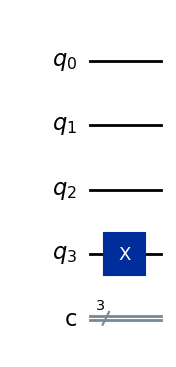

In [3]:
qpe = QuantumCircuit(4, 3)
qpe.x(3)
qpe.draw(output='mpl')

Next, we apply Hadamard gates to the counting qubits:

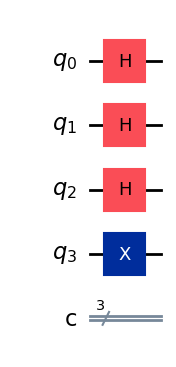

In [4]:
for qubit in range(3):
    qpe.h(qubit)
qpe.draw(output='mpl')

Next we perform the controlled unitary operations.

We'll use Qiskit's [`PhaseGate`](https://qiskit.org/documentation/stubs/qiskit.circuit.library.PhaseGate.html) to create the $T$ operation. The phase gate does the transformation $P|1\rangle = e^{i\lambda}|1\rangle$, where $\lambda$ is the angle we provide. Since we want to implement $T$, which performs $T|1\rangle = e^{2\pi i \theta}|1\rangle$, we need to set $\lambda = \tfrac{2 \pi}{8} = \pi/4$.

Also remember that Qiskit orders its qubits the opposite way round to the circuit diagram in the overview.

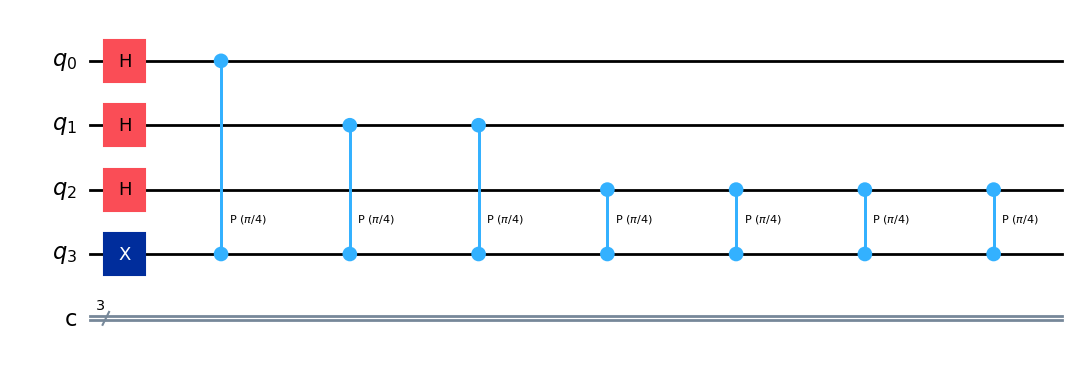

In [5]:
repetitions = 1
for counting_qubit in range(3):
    for i in range(repetitions):
        qpe.cp(math.pi/4, counting_qubit, 3); # controlled-T
    repetitions *= 2
qpe.draw(output='mpl')

We apply the inverse quantum Fourier transformation to convert the state of the counting register, then measure the counting register:

/var/folders/02/nmlm5sxj1m7bzjrjkc_zlqzc0000gr/T/ipykernel_93408/2632721070.py:3: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qpe = qpe.compose(QFT(3, inverse=True), [0,1,2])


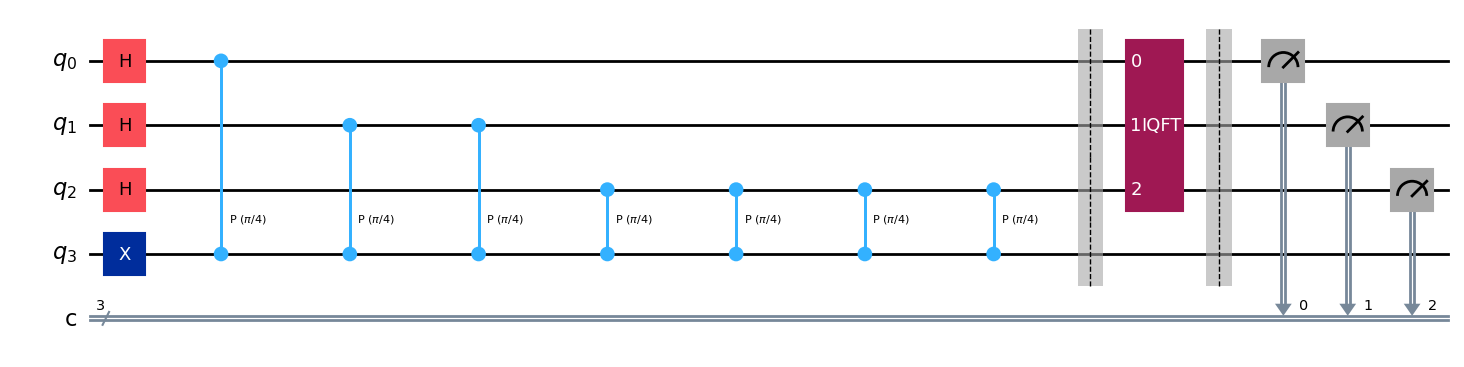

In [6]:
qpe.barrier()
# Apply inverse QFT
qpe = qpe.compose(QFT(3, inverse=True), [0,1,2])
# Measure
qpe.barrier()
for n in range(3):
    qpe.measure(n,n)

qpe.draw(output='mpl')

### Results <a id='results'></a>

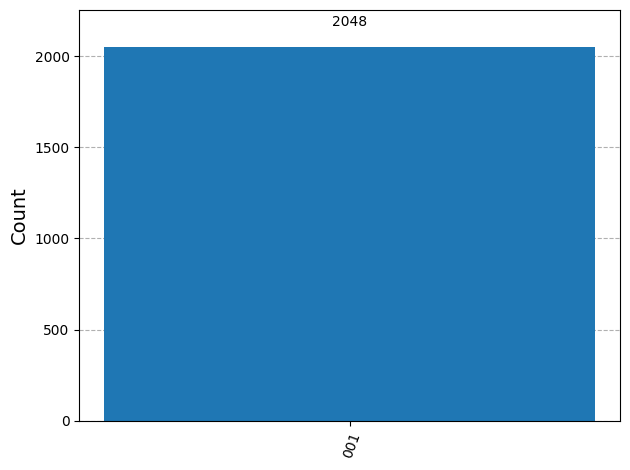

In [7]:
aer_sim = AerSimulator()
shots = 2048
t_qpe = transpile(qpe, aer_sim)
results = aer_sim.run(t_qpe, shots=shots).result()
answer = results.get_counts()

plot_histogram(answer)

We see we get one result (`001`) with certainty, which translates to the decimal: `1`. We now need to divide our result (`1`) by $2^n$ to get $\theta$:



$$ \theta = \frac{1}{2^3} = \frac{1}{8} $$



This is exactly the result we expected!

## Example: Getting More Precision <a id='getting_more_precision'></a>

### The Problem <a id='the_problem'></a>

Instead of a $T$-gate, let’s use a gate with $\theta = \frac{1}{3}$.

In the cell below, we set up our circuit as we did with the last example.

We'll use Qiskit's [`PhaseGate`](https://qiskit.org/documentation/stubs/qiskit.circuit.library.PhaseGate.html) again, which does $P|1\rangle = e^{i\lambda}|1\rangle$. Since we want to implement $U|1\rangle = e^{2\pi i \tfrac{1}{3}}|1\rangle$, we need to set $\lambda = \tfrac{2 \pi}{3}$.

/var/folders/02/nmlm5sxj1m7bzjrjkc_zlqzc0000gr/T/ipykernel_93408/1072752855.py:20: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qpe2 = qpe2.compose(QFT(3, inverse=True), [0,1,2])


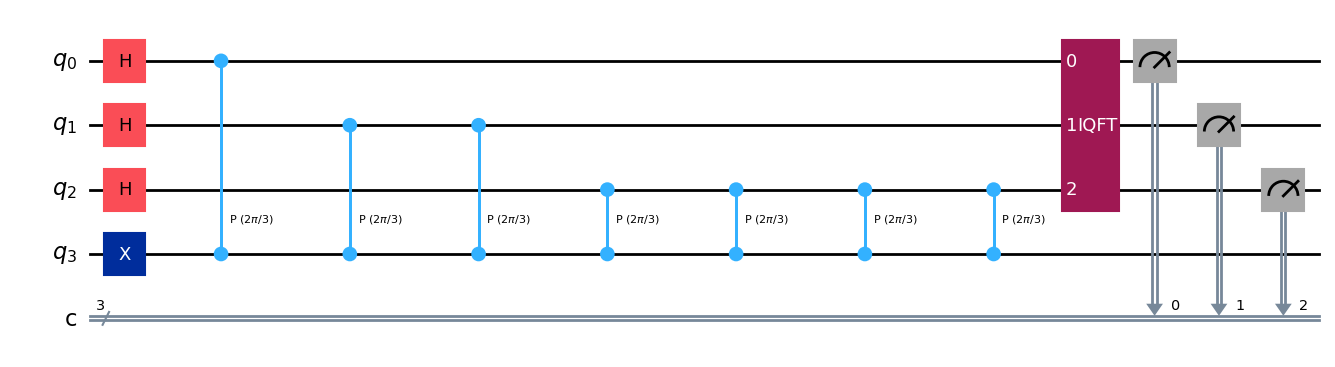

In [8]:
# Create and set up circuit
qpe2 = QuantumCircuit(4, 3)

# Apply H-Gates to counting qubits:
for qubit in range(3):
    qpe2.h(qubit)

# Prepare our eigenstate |psi>:
qpe2.x(3)

# Do the controlled-U operations:
angle = 2*math.pi/3
repetitions = 1
for counting_qubit in range(3):
    for i in range(repetitions):
        qpe2.cp(angle, counting_qubit, 3);
    repetitions *= 2

# Do the inverse QFT:
qpe2 = qpe2.compose(QFT(3, inverse=True), [0,1,2])

# Measure of course!
for n in range(3):
    qpe2.measure(n,n)

qpe2.draw(output='mpl')

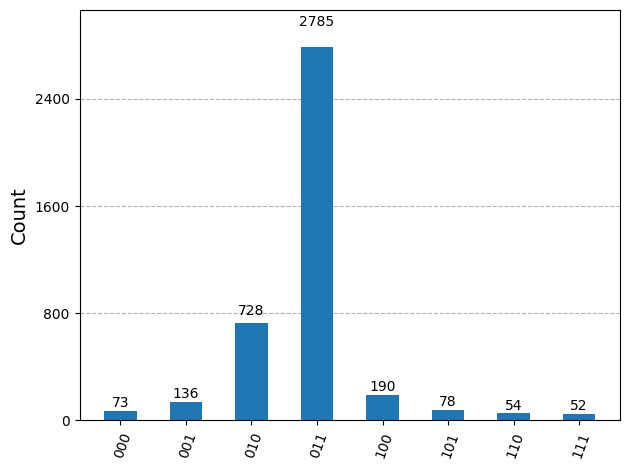

In [9]:
# Let's see the results!
aer_sim = AerSimulator()
shots = 4096
t_qpe2 = transpile(qpe2, aer_sim)
results = aer_sim.run(t_qpe2, shots=shots).result()
answer = results.get_counts()

plot_histogram(answer)

We are expecting the result $\theta = 0.3333\dots$, and we see our most likely results are `010(bin) = 2(dec)` and `011(bin) = 3(dec)`. These two results would tell us that $\theta = 0.25$ (off by 25%) and $\theta = 0.375$ (off by 13%) respectively. The true value of $\theta$ lies between the values we can get from our counting bits, and this gives us uncertainty and imprecision.

### The Solution <a id='the_solution'></a>
To get more precision we simply add more counting qubits. We are going to add two more counting qubits:

/var/folders/02/nmlm5sxj1m7bzjrjkc_zlqzc0000gr/T/ipykernel_93408/704783581.py:20: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qpe3 = qpe3.compose(QFT(5, inverse=True), range(5))


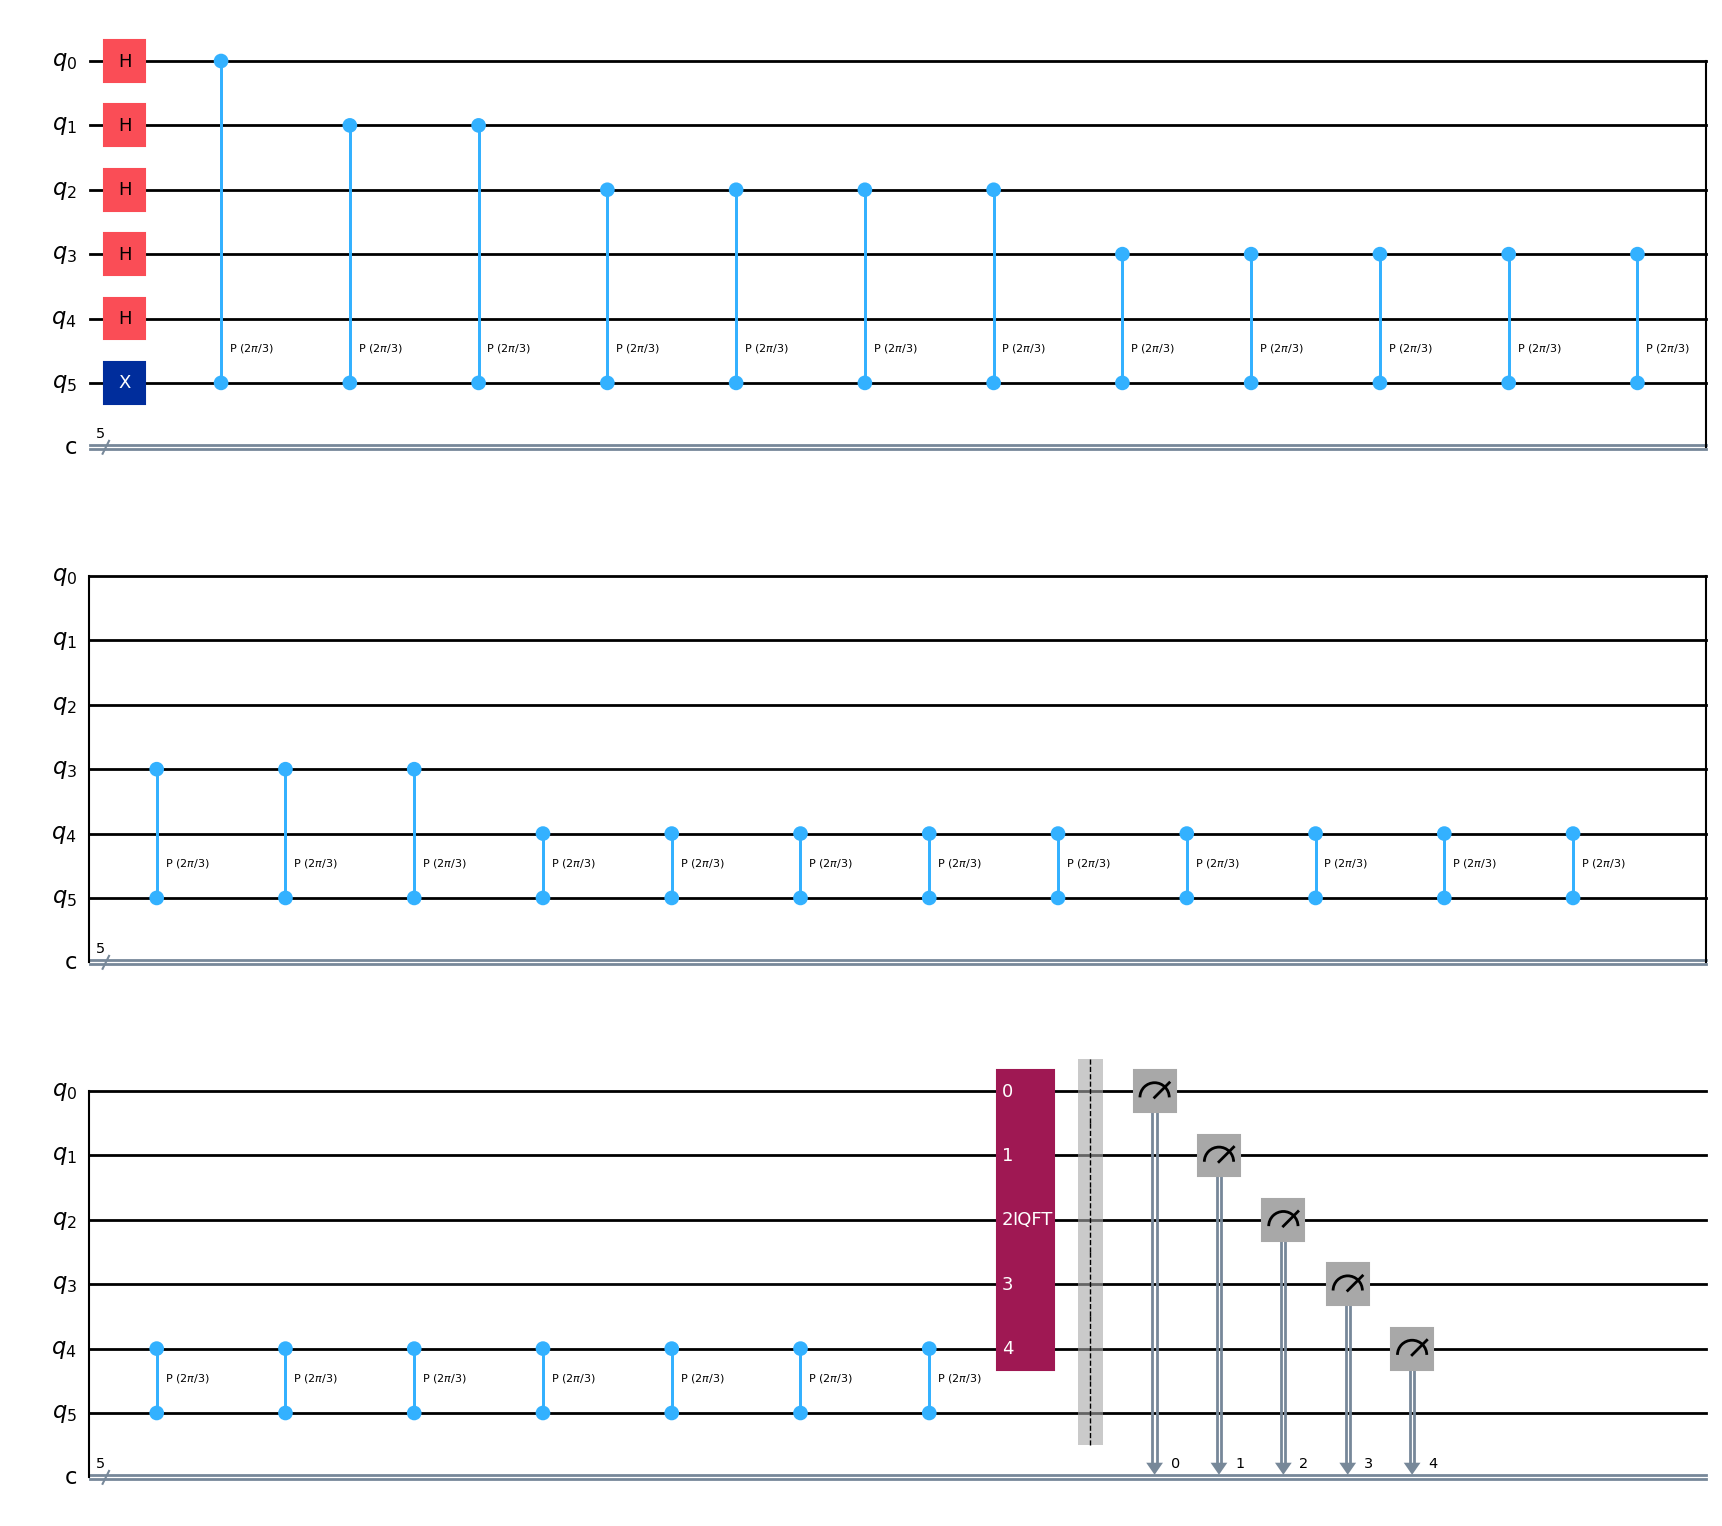

In [10]:
# Create and set up circuit
qpe3 = QuantumCircuit(6, 5)

# Apply H-Gates to counting qubits:
for qubit in range(5):
    qpe3.h(qubit)

# Prepare our eigenstate |psi>:
qpe3.x(5)

# Do the controlled-U operations:
angle = 2*math.pi/3
repetitions = 1
for counting_qubit in range(5):
    for i in range(repetitions):
        qpe3.cp(angle, counting_qubit, 5);
    repetitions *= 2

# Do the inverse QFT:
qpe3 = qpe3.compose(QFT(5, inverse=True), range(5))

# Measure of course!
qpe3.barrier()
for n in range(5):
    qpe3.measure(n,n)

qpe3.draw(output='mpl')

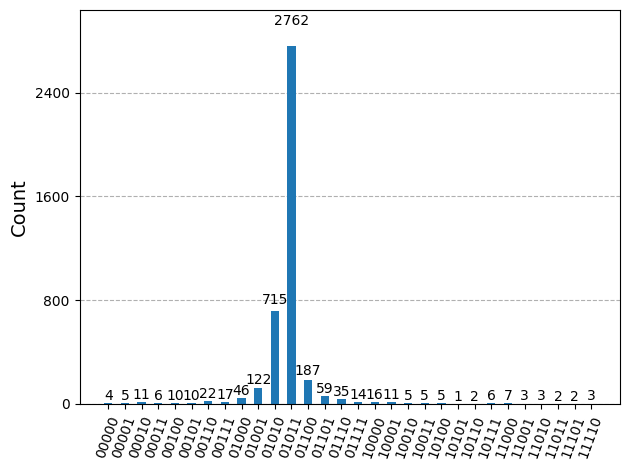

In [11]:
# Let's see the results!
aer_sim = AerSimulator()
shots = 4096
t_qpe3 = transpile(qpe3, aer_sim)
results = aer_sim.run(t_qpe3, shots=shots).result()
answer = results.get_counts()

plot_histogram(answer)

The two most likely measurements are now `01011` (decimal 11) and `01010` (decimal 10). Measuring these results would tell us $\theta$ is:

$$
\theta = \frac{11}{2^5} = 0.344,\;\text{  or  }\;\; \theta = \frac{10}{2^5} = 0.313
$$

These two results differ from $\frac{1}{3}$ by 3% and 6% respectively. A much better precision!

## Noisy Simulation

On real quantum hardware, gates are imperfect. We can model this using a **depolarizing noise model**, where each gate has a tunable probability `error_rate` of introducing a random error. We apply this error to all single-qubit and two-qubit gates in the circuit, then compare results across several noise levels.

In [12]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

def build_noise_model(error_rate):
    """Build a depolarizing noise model with tunable error_rate on all gates."""
    noise_model = NoiseModel()
    if error_rate == 0:
        return noise_model

    error_1q = depolarizing_error(error_rate, 1)
    error_2q = depolarizing_error(error_rate, 2)

    for gate in ['h', 'x', 'z', 'p', 's', 't', 'sdg', 'tdg', 'sx', 'rz', 'ry', 'rx', 'id']:
        noise_model.add_all_qubit_quantum_error(error_1q, gate)
    for gate in ['cx', 'cz', 'cp', 'swap', 'ecr', 'rzz', 'rxx']:
        noise_model.add_all_qubit_quantum_error(error_2q, gate)

    return noise_model

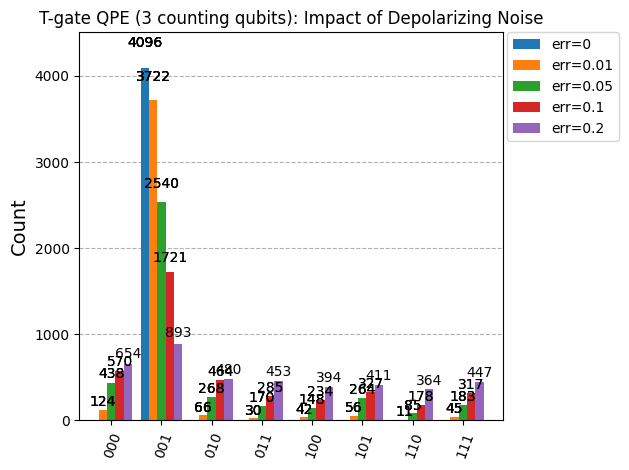

In [13]:
# --- Noisy simulation: T-gate QPE (3 counting qubits) ---
error_rates = [0, 0.01, 0.05, 0.1, 0.2]
shots = 4096

noisy_counts = {}
for rate in error_rates:
    noise_model = build_noise_model(rate)
    sim = AerSimulator(noise_model=noise_model)
    t_circ = transpile(qpe, sim)
    result = sim.run(t_circ, shots=shots).result()
    noisy_counts[f"err={rate}"] = result.get_counts()

plot_histogram(list(noisy_counts.values()), legend=list(noisy_counts.keys()),
               title="T-gate QPE (3 counting qubits): Impact of Depolarizing Noise")

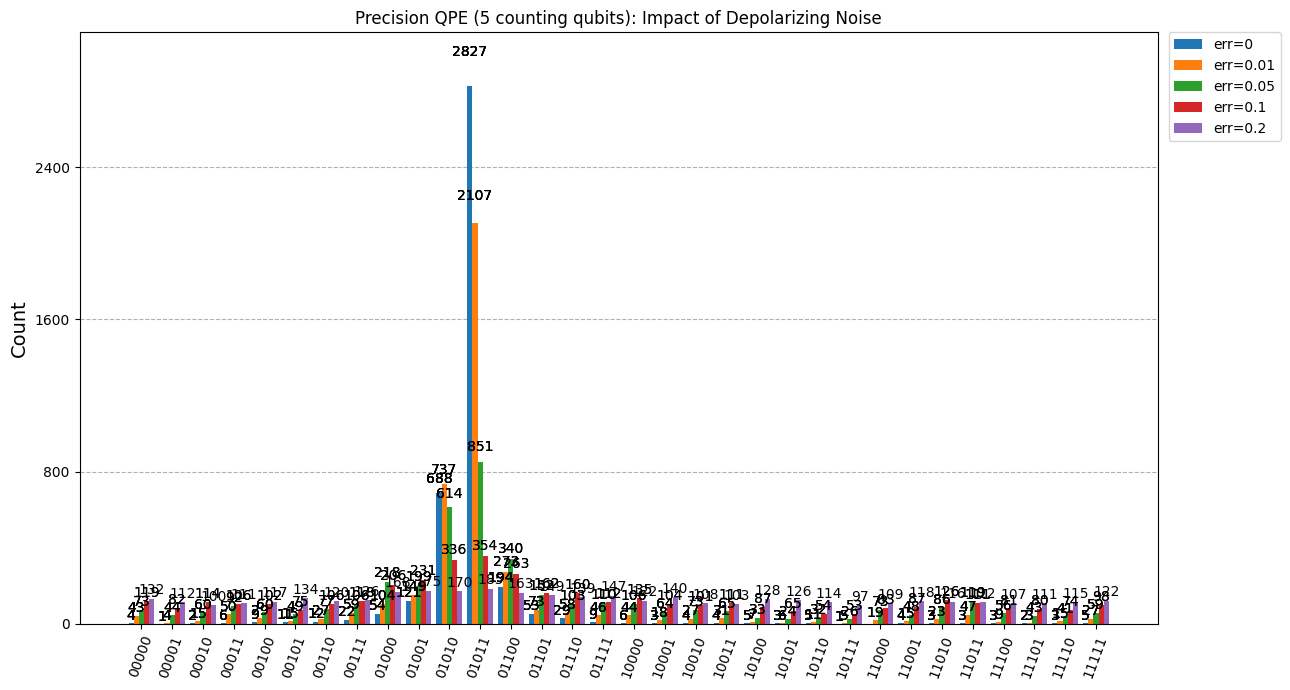

In [16]:
# --- Noisy simulation: Precision QPE (5 counting qubits) ---
error_rates = [0, 0.01, 0.05, 0.1, 0.2]
shots = 4096

noisy_counts = {}
for rate in error_rates:
    noise_model = build_noise_model(rate)
    sim = AerSimulator(noise_model=noise_model)
    t_circ = transpile(qpe3, sim)
    result = sim.run(t_circ, shots=shots).result()
    noisy_counts[f"err={rate}"] = result.get_counts()

plot_histogram(list(noisy_counts.values()), legend=list(noisy_counts.keys()),
               title="Precision QPE (5 counting qubits): Impact of Depolarizing Noise", figsize=(13, 7))